# 🧠 Introduction to LLM Instruction Fine-Tuning
### Mistral-7B + QLoRA on Wikipedia — Google Colab T4

This notebook walks through the full pipeline for **instruction-following fine-tuning** of a large language model, from raw text to a chat-ready model:

```
Wikipedia Articles
      │
      ▼
 Instruction/Response Pairs  ← template-based generation
      │
      ▼
 Mistral-7B (4-bit quantized)  ← fits in 16 GB T4 VRAM
      │
      ▼
   QLoRA Fine-Tuning  ← only trains ~0.5% of parameters
      │
      ▼
  Evaluation on topic questions
```

### Key concepts covered
| Concept | What it is |
|---------|------------|
| **Instruction tuning** | Teaching an LLM to follow natural-language commands |
| **QLoRA** | Quantized LoRA — fine-tune a 4-bit model with rank-decomposed adapters |
| **SFT** | Supervised Fine-Tuning — train on (instruction, response) pairs |
| **PEFT** | Parameter-Efficient Fine-Tuning — update <1% of weights |

> 💡 **Before running:** `Runtime → Change runtime type → T4 GPU`
>
> 🔑 **HuggingFace token required** for Mistral weights — get one free at [huggingface.co/settings/tokens](https://huggingface.co/settings/tokens) (read access is enough).

---
## 1. 📦 Install Dependencies

In [ ]:
%%capture
# Core fine-tuning stack
!pip install transformers==4.40.2
!pip install peft==0.10.0
!pip install trl==0.8.6
#ChatGPT addition
!pip install accelerate==0.30.1
!pip install datasets==2.19.1
# Wikipedia fetching & text processing
!pip install wikipedia-api
!pip install sentencepiece

print("✅ All packages installed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.0/138.0 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 80.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 92.2 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.18.0
    Uninstalling huggingface_hub-1.18.0:
      Successfully uninstalled huggingface_hub-1.18.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.22.2
    Uninstalling tokenizers-0.22.2:
      Successfully uninstalled tokenizers-0.22.2
  Attempting uninstall: transformers
    Found existing installation: transformers 5.10.2
    Uninstalling transformers-5.10.2:
      Successfully uninstalled transformers-5.10.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the 

In [ ]:
%%capture
!pip uninstall -y bitsandbytes triton
!pip install triton==3.6.0
!pip install bitsandbytes --no-cache-dir
!pip install -U transformers
!pip install -U accelerate
!pip install -U trl -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.4/693.4 kB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 54.5 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 0.36.2
    Uninstalling huggingface_hub-0.36.2:
      Successfully uninstalled huggingface_hub-0.36.2
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.19.1
    Uninstalling tokenizers-0.19.1:
      Successfully uninstalled tokenizers-0.19.1
  Attempting uninstall: transformers
    Found existing installation: transformers 4.40.2
    Uninstalling transformers-4.40.2:
      Successfully uninstalled transformers-4.40.2


In [ ]:
!pip list | grep -E "torch|transformers|peft|bitsandbytes|triton"

bitsandbytes                             0.49.2
peft                                     0.10.0
sentence-transformers                    5.5.1
torch                                    2.11.0+cu128
torchao                                  0.10.0
torchaudio                               2.11.0+cu128
torchcodec                               0.11.0+cu128
torchdata                                0.11.0
torchsummary                             1.5.1
torchtune                                0.6.1
torchvision                              0.26.0+cu128
transformers                             5.12.1
triton                                   3.6.0


1. bitsandbytes                             0.49.2
2. peft                                     0.10.0
3. sentence-transformers                    5.5.1
4. torch                                    2.11.0+cu128
5. torchao                                  0.10.0
6. torchaudio                               2.11.0+cu128
7. torchcodec                               0.11.0+cu128
8. torchdata                                0.11.0
9. torchsummary                             1.5.1
10. torchtune                                0.6.1
11. torchvision                              0.26.0+cu128
12. transformers                             5.12.1
13.triton                                   3.6.0

In [ ]:
import os
import re
import json
import random
import textwrap
import warnings
warnings.filterwarnings("ignore")

import torch
import numpy as np
import wikipediaapi

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    TrainingArguments,
    pipeline,
    set_seed,
)
from peft import LoraConfig, get_peft_model, TaskType, PeftModel
from trl import SFTTrainer #, DataCollatorForCompletionOnlyLM

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"✅ Imports OK")
print(f"   Device  : {device}")
if device == "cuda":
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb  = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"   GPU     : {gpu_name}")
    print(f"   VRAM    : {vram_gb:.1f} GB")
else:
    print("   ⚠️  No GPU found — switch runtime to T4 for best results")

✅ Imports OK
   Device  : cuda
   GPU     : Tesla T4
   VRAM    : 15.6 GB


In [ ]:
import trl
print(dir(trl))

['BEMACallback', 'DPOConfig', 'DPOTrainer', 'DatasetMixtureConfig', 'GRPOConfig', 'GRPOTrainer', 'KTOConfig', 'KTOTrainer', 'LogCompletionsCallback', 'ModelConfig', 'RLOOConfig', 'RLOOTrainer', 'RewardConfig', 'RewardTrainer', 'RichProgressCallback', 'SFTConfig', 'SFTTrainer', 'ScriptArguments', 'SyncRefModelCallback', 'TrlParser', 'WeaveCallback', '__all__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_class_to_module', '_import_structure', '_modules', '_name', '_objects', 'add_response_schema', 'apply_chat_template', 'chat_template_utils', 'clone_chat_template', 'create_reference_model', 'data_utils', 'extract_prompt', 'get_dataset', 'get_kbit_device_map', 'get_peft_config', 'get_quantization_config', 'get_training_chat_template', 'init_zero_verbose', 'is_conversational', 'is_conversational_from_value', 'maybe_apply_chat_template', 'maybe_convert_to_chatml', 'maybe_extract_prompt', 'maybe_unpair_preference_dataset', 'models', 'pack_dataset

---
## 2. 🔑 HuggingFace Authentication

Mistral weights are gated — you need to:
1. Accept the licence at [huggingface.co/mistralai/Mistral-7B-v0.1](https://huggingface.co/mistralai/Mistral-7B-v0.1)
2. Paste a **read-access token** below.

In [ ]:
from huggingface_hub import login
from google.colab import userdata

# ── Recommended: store your token as a Colab Secret named HF_TOKEN ──────────
# In Colab: click the 🔑 key icon (left sidebar) → add secret HF_TOKEN
try:
    HF_TOKEN = userdata.get("HF_TOKEN")
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("✅ Logged in via Colab secret")
except Exception:
    # Fallback: paste token directly
    HF_TOKEN = "hf_YOUR_TOKEN_HERE"   # ← replace with your token
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("✅ Logged in via inline token")

✅ Logged in via Colab secret


---
## 3. 📖 Build the Wikipedia Dataset

We fetch a curated set of Wikipedia articles on **scientific and technical topics**, then split them into short chunks — each chunk becomes the context for one instruction/response pair.

### Topics selected
These cover a variety of knowledge areas so the model practises diverse instructions:

In [ ]:
# Wikipedia topics to fetch
TOPICS = [
    "Machine learning",
    "Neural network",
    "Natural language processing",
    "Python (programming language)",
    "Transformer (deep learning architecture)",
    "Photosynthesis",
    "Climate change",
    "DNA",
    "Quantum computing",
    "Black hole",
]

wiki = wikipediaapi.Wikipedia(
    user_agent="InstructionTuningNotebook/1.0",
    language="en"
)

def fetch_article(title: str, max_chars: int = 8000) -> dict | None:
    """Fetch a Wikipedia article and return title + truncated text."""
    page = wiki.page(title)
    if not page.exists():
        print(f"  ⚠️  Page not found: {title}")
        return None
    text = page.text[:max_chars]
    return {"title": page.title, "text": text}

articles = []
for topic in TOPICS:
    art = fetch_article(topic)
    if art:
        articles.append(art)
        print(f"  ✅  {art['title']:<45}  {len(art['text']):>6} chars")

print(f"\nFetched {len(articles)} articles")

  ✅  Machine learning                                 8000 chars
  ✅  Neural network                                   5304 chars
  ✅  Natural language processing                      8000 chars
  ✅  Python (programming language)                    8000 chars
  ✅  Transformer (deep learning)                      8000 chars
  ✅  Photosynthesis                                   8000 chars
  ✅  Climate change                                   8000 chars
  ✅  DNA                                              8000 chars
  ✅  Quantum computing                                8000 chars
  ✅  Black hole                                       8000 chars

Fetched 10 articles


In [ ]:
def chunk_text(text: str, chunk_size: int = 400, overlap: int = 50) -> list[str]:
    """
    Split text into overlapping sentence-aware chunks.
    Tries to break at sentence boundaries.
    """
    # Split into sentences
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    chunks, current, current_len = [], [], 0

    for sentence in sentences:
        wlen = len(sentence.split())
        if current_len + wlen > chunk_size and current:
            chunks.append(" ".join(current))
            # Keep last `overlap` words for continuity
            overlap_words = " ".join(current).split()[-overlap:]
            current = [" ".join(overlap_words)]
            current_len = len(overlap_words)
        current.append(sentence)
        current_len += wlen

    if current:
        chunks.append(" ".join(current))

    # Filter out very short chunks
    return [c for c in chunks if len(c.split()) >= 40]


# Build corpus: list of {title, chunk}
corpus = []
for art in articles:
    chunks = chunk_text(art["text"])
    for c in chunks:
        corpus.append({"title": art["title"], "chunk": c})

print(f"Total chunks: {len(corpus)}")
print(f"\nExample chunk from '{corpus[0]['title']}':\n")
print(textwrap.fill(corpus[0]["chunk"], width=90))

Total chunks: 39

Example chunk from 'Machine learning':

Machine learning (ML) is a field of study in artificial intelligence concerned with the
development and study of statistical algorithms that can learn from  data and generalize
to unseen data, and thus perform tasks without being explicitly programmed. Advances in
the field of deep learning have allowed neural networks, a class of statistical
algorithms, to surpass many previous machine learning approaches in performance.
Statistics and mathematical optimisation methods compose the foundations of machine
learning. Data mining is a related field of study, focusing on exploratory data analysis
(EDA) through unsupervised learning. From a theoretical viewpoint, probably approximately
correct learning provides a mathematical and statistical framework for describing machine
learning. Most traditional machine learning and deep learning algorithms can be described
as empirical risk minimisation under this framework. History The term mac

---
## 4. 🏗️ Generate Instruction / Response Pairs

We use **template-based generation** — no second LLM required. Each Wikipedia chunk is paired with one of several instruction templates to create a diverse set of training examples.

```
chunk  ──→  template picker  ──→  (instruction, response) pair
```

All pairs are formatted in **Mistral's chat template** (`[INST] … [/INST]`).

In [ ]:
# ── Instruction templates ────────────────────────────────────────────────────
# Each template is a (instruction_fn, response_fn) pair.
# instruction_fn(title, chunk) → instruction string
# response_fn(title, chunk)   → response string

TEMPLATES = [
    {
        "name": "explain",
        "instruction": lambda t, c: f"Explain the following passage about {t} in simple terms.",
        "response":    lambda t, c: c,
    },
    {
        "name": "summarize",
        "instruction": lambda t, c: f"Summarize the key points of this {t} excerpt in 2–3 sentences.",
        "response":    lambda t, c: _summarize_chunk(c),
    },
    {
        "name": "qa",
        "instruction": lambda t, c: f"Based on the following text about {t}, answer: {_extract_question(c, t)}",
        "response":    lambda t, c: _extract_answer(c),
    },
    {
        "name": "define",
        "instruction": lambda t, c: f"What is {t}? Use the provided text to answer.",
        "response":    lambda t, c: c,
    },
    {
        "name": "list",
        "instruction": lambda t, c: f"List the main concepts or facts mentioned in this passage about {t}.",
        "response":    lambda t, c: _bullet_facts(c),
    },
    {
        "name": "context_qa",
        "instruction": lambda t, c: (
            f"Read the following context and answer the question.\n\n"
            f"Context: {c}\n\nQuestion: What does this passage tell us about {t}?"
        ),
        "response":    lambda t, c: _first_sentences(c, 3),
    },
]


# ── Helper functions ─────────────────────────────────────────────────────────

def _first_sentences(text: str, n: int) -> str:
    """Return first n sentences of text."""
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    return " ".join(sentences[:n])

def _summarize_chunk(chunk: str) -> str:
    """Simple extractive summary: first + last sentence."""
    sentences = re.split(r'(?<=[.!?])\s+', chunk.strip())
    if len(sentences) <= 3:
        return chunk
    return sentences[0] + " " + sentences[len(sentences)//2] + " " + sentences[-1]

def _extract_question(chunk: str, title: str) -> str:
    """Generate a factoid question from the first sentence."""
    first = re.split(r'(?<=[.!?])\s+', chunk.strip())[0]
    # Replace subject with 'What' to form a question
    nouns = re.findall(r'\b[A-Z][a-z]+\b', first)
    if nouns:
        return f"What is the role of {nouns[0]} in {title}?"
    return f"What does the passage say about {title}?"

def _extract_answer(chunk: str) -> str:
    """Return the first two sentences as the answer."""
    return _first_sentences(chunk, 2)

def _bullet_facts(chunk: str) -> str:
    """Turn sentences into a bullet list."""
    sentences = re.split(r'(?<=[.!?])\s+', chunk.strip())
    bullets = [f"• {s.strip()}" for s in sentences if len(s.split()) > 6]
    return "\n".join(bullets[:6])  # max 6 bullets


print("✅ Templates and helpers defined")

✅ Templates and helpers defined


In [ ]:
# ── Mistral chat format ──────────────────────────────────────────────────────
# Mistral uses: <s>[INST] {instruction} [/INST] {response}</s>

def format_mistral(instruction: str, response: str) -> str:
    return f"<s>[INST] {instruction.strip()} [/INST] {response.strip()} </s>"


random.seed(42)

pairs = []
for item in corpus:
    tmpl = random.choice(TEMPLATES)
    try:
        instruction = tmpl["instruction"](item["title"], item["chunk"])
        response    = tmpl["response"](item["title"], item["chunk"])

        # Skip degenerate samples
        if len(response.split()) < 10:
            continue

        pairs.append({
            "title":       item["title"],
            "template":    tmpl["name"],
            "instruction": instruction,
            "response":    response,
            "text":        format_mistral(instruction, response),
        })
    except Exception as e:
        pass  # skip malformed chunks

random.shuffle(pairs)
print(f"Generated {len(pairs)} instruction/response pairs")

# Template distribution
from collections import Counter
dist = Counter(p["template"] for p in pairs)
print("\nTemplate distribution:")
for tmpl_name, cnt in sorted(dist.items()):
    bar = "█" * cnt
    print(f"  {tmpl_name:<12} {cnt:>3}  {bar}")

Generated 39 instruction/response pairs

Template distribution:
  context_qa     9  █████████
  define         4  ████
  explain        9  █████████
  list           7  ███████
  qa             2  ██
  summarize      8  ████████


In [ ]:
# Preview a few examples
print("=" * 70)
print("SAMPLE INSTRUCTION/RESPONSE PAIRS")
print("=" * 70)
for p in random.sample(pairs, min(3, len(pairs))):
    print(f"\n📌 Topic   : {p['title']}")
    print(f"📝 Template: {p['template']}")
    print(f"\n[INSTRUCTION]\n{textwrap.fill(p['instruction'], 80)}")
    print(f"\n[RESPONSE]\n{textwrap.fill(p['response'][:300], 80)}")
    print("-" * 70)

SAMPLE INSTRUCTION/RESPONSE PAIRS

📌 Topic   : Climate change
📝 Template: explain

[INSTRUCTION]
Explain the following passage about Climate change in simple terms.

[RESPONSE]
Present-day climate change includes both global warming—the ongoing increase in
global average temperature—and its wider effects on Earth's climate system.
Climate change in a broader sense also includes previous long-term changes to
Earth's climate. The modern-day rise in global temperatures is dri
----------------------------------------------------------------------

📌 Topic   : Machine learning
📝 Template: context_qa

[INSTRUCTION]
Read the following context and answer the question.  Context: Machine learning
(ML) is a field of study in artificial intelligence concerned with the
development and study of statistical algorithms that can learn from  data and
generalize to unseen data, and thus perform tasks without being explicitly
programmed. Advances in the field of deep learning have allowed neural networks,

In [ ]:
# Train/validation split (90/10)
split = int(len(pairs) * 0.9)
train_pairs = pairs[:split]
val_pairs   = pairs[split:]

train_dataset = Dataset.from_list([{"text": p["text"]} for p in train_pairs])
val_dataset   = Dataset.from_list([{"text": p["text"]} for p in val_pairs])

print(f"Train samples : {len(train_dataset)}")
print(f"Val samples   : {len(val_dataset)}")
print(f"\nFirst training sample (truncated):")
print(train_dataset[0]["text"][:300], "…")

Train samples : 35
Val samples   : 4

First training sample (truncated):
<s>[INST] Summarize the key points of this Climate change excerpt in 2–3 sentences. [/INST] scientists, politicians and media may use the terms climate crisis or climate emergency to talk about climate change, and may use the term global heating instead of global warming. Climate information for tha …


---
## 5. 🔬 Load Mistral-7B — 4-bit Quantized

### Why 4-bit (QLoRA)?

| Precision | VRAM for 7B | Fits T4 (16 GB)? |
|-----------|------------|------------------|
| fp32      | ~28 GB     | ❌ |
| fp16      | ~14 GB     | ✅ (tight) |
| **int4**  | **~4 GB**  | ✅ ✅ (comfortable) |

We use `BitsAndBytesConfig` with `nf4` (NormalFloat4) — the quantization format used in the original QLoRA paper, which preserves model quality better than plain int4.

In [ ]:
MODEL_ID = "mistralai/Mistral-7B-v0.1"

# ── 4-bit quantization config ────────────────────────────────────────────────
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",          # NormalFloat4 — best quality 4-bit
    bnb_4bit_compute_dtype=torch.float16,  # compute in fp16 for speed
    bnb_4bit_use_double_quant=True,     # quantize the quantization constants too
)

print("✅ BitsAndBytes config ready")
print(f"   Quant type         : nf4")
print(f"   Compute dtype      : float16")
print(f"   Double quantization: True")

✅ BitsAndBytes config ready
   Quant type         : nf4
   Compute dtype      : float16
   Double quantization: True


In [ ]:
print(f"Loading {MODEL_ID} in 4-bit … (this takes ~2 min on first run)")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    padding_side="right",   # required for SFT with left-padded batches
    add_eos_token=True,
    add_bos_token=True,
    token=HF_TOKEN,
)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",      # auto-place layers across GPU/CPU
    token=HF_TOKEN,
)
model.config.use_cache = False   # required for gradient checkpointing

# Memory report
if device == "cuda":
    alloc  = torch.cuda.memory_allocated() / 1e9
    reserv = torch.cuda.memory_reserved()  / 1e9
    print(f"\n✅ Model loaded")
    print(f"   VRAM allocated : {alloc:.2f} GB")
    print(f"   VRAM reserved  : {reserv:.2f} GB")

total_params = sum(p.numel() for p in model.parameters())
print(f"   Total params   : {total_params/1e9:.2f} B")

Loading mistralai/Mistral-7B-v0.1 in 4-bit … (this takes ~2 min on first run)


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]


✅ Model loaded
   VRAM allocated : 4.13 GB
   VRAM reserved  : 4.27 GB
   Total params   : 3.75 B


---
## 6. 🎛️ Configure QLoRA (LoRA Adapters)

### How LoRA works

Instead of updating all 7 billion weights, LoRA **freezes** the original model and **injects small trainable rank-decomposition matrices** (adapters) into the attention layers:

```
W_original (frozen, 4096×4096)  +  A (4096×r)  ×  B (r×4096)
                                         └── only these are trained
```

With rank `r=8`, we train ~0.4% of parameters — yet the model learns new behaviour.

| Hyperparameter | Value | Effect |
|----------------|-------|--------|
| `r` | 8 | LoRA rank — higher = more capacity |
| `lora_alpha` | 16 | Scaling factor (typically 2×r) |
| `lora_dropout` | 0.05 | Light regularisation |
| `target_modules` | q,k,v,o projections | Where adapters are injected |

In [ ]:
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,                    # rank — keep low for speed
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",    # MLP layers
    ],
    inference_mode=False,
)

model = get_peft_model(model, lora_config)

# Count trainable vs frozen parameters
trainable   = sum(p.numel() for p in model.parameters() if p.requires_grad)
total       = sum(p.numel() for p in model.parameters())
pct         = 100 * trainable / total

print(f"✅ LoRA adapters injected")
print(f"   Trainable params : {trainable:>12,}  ({pct:.2f}% of total)")
print(f"   Frozen params    : {total - trainable:>12,}")
print(f"   Total params     : {total:>12,}")

✅ LoRA adapters injected
   Trainable params :   20,971,520  (0.56% of total)
   Frozen params    : 3,752,071,168
   Total params     : 3,773,042,688


---
## 7. 🏋️ Fine-Tune with SFTTrainer

We use **TRL's SFTTrainer** which:
- Handles tokenization, padding, and packing automatically
- Masks the instruction tokens so the model **only learns to predict the response**
- Supports gradient checkpointing to reduce VRAM use at the cost of ~20% speed

**Training is intentionally short** (1 epoch, small dataset) — the goal is to see the mechanics work, not to achieve production accuracy.

In [ ]:
OUTPUT_DIR = "./mistral-qlora-wikipedia"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # ── Epoch / steps ─────────────────────────────────────────────────────
    num_train_epochs=1,             # 1 epoch for speed — increase for quality
    max_steps=-1,                   # -1 = use num_train_epochs

    # ── Batch size & accumulation ─────────────────────────────────────────
    per_device_train_batch_size=2,  # small batch to fit T4
    gradient_accumulation_steps=4,  # effective batch size = 2 × 4 = 8
    per_device_eval_batch_size=2,

    # ── Optimiser ─────────────────────────────────────────────────────────
    optim="paged_adamw_8bit",       # 8-bit AdamW — saves VRAM
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.03,

    # ── Memory ────────────────────────────────────────────────────────────
    gradient_checkpointing=True,    # trade speed for VRAM
    #fp16=True,                      # mixed precision
    bf16=True,
    # ── Logging & saving ──────────────────────────────────────────────────
    logging_steps=5,
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=2,
    load_best_model_at_end=False,

    # ── Misc ──────────────────────────────────────────────────────────────
    seed=42,
    report_to="none",               # disable W&B / TensorBoard
#    group_by_length=True,           # group similar-length samples to reduce padding
    max_grad_norm=0.3,
)

print("✅ Training arguments set")
print(f"   Effective batch size : {training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps}")
print(f"   Max sequence length  : 512 (set in SFTTrainer below)")

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


✅ Training arguments set
   Effective batch size : 8
   Max sequence length  : 512 (set in SFTTrainer below)


In [ ]:
# Response-only training: only compute loss on the [/INST] ... </s> part
from trl import SFTConfig
response_template = " [/INST]"

trainer = SFTTrainer(
    model=model,
    args=SFTConfig(
        output_dir=OUTPUT_DIR,
        num_train_epochs=10,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,
        per_device_eval_batch_size=2,
        optim="paged_adamw_8bit",
        learning_rate=2e-4,
        lr_scheduler_type="cosine",
        warmup_ratio=0.03,
        gradient_checkpointing=True,
        #fp16=True,
        bf16=True,
        logging_steps=5,
        eval_strategy="steps",
        eval_steps=20,
        save_strategy="steps",
        save_steps=50,
        save_total_limit=2,
        seed=42,
        report_to="none",
        max_grad_norm=0.3,
        max_length=512,       # moved into SFTConfig
        packing=False,
    ),
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    #dataset_text_field="text",
)

print("✅ SFTTrainer ready")

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Adding EOS to train dataset:   0%|          | 0/35 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/35 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/4 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/4 [00:00<?, ? examples/s]

✅ SFTTrainer ready


In [ ]:
print("🚀 Starting training …")
print(f"   Samples     : {len(train_dataset)}")
print(f"   Epochs      : {training_args.num_train_epochs}")
print(f"   Est. time   : ~5–15 min on T4\n")

train_result = trainer.train()

print("\n✅ Training complete!")
metrics = train_result.metrics
print(f"   Train loss      : {metrics.get('train_loss', 'N/A'):.4f}")
print(f"   Train runtime   : {metrics.get('train_runtime', 0):.0f} s")
print(f"   Samples/second  : {metrics.get('train_samples_per_second', 0):.1f}")

🚀 Starting training …
   Samples     : 35
   Epochs      : 1
   Est. time   : ~5–15 min on T4



Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,0.651934,2.545216,1.194499,0.523878,47204.000000
40,0.119749,3.146611,0.813707,0.532098,94408.000000
50,0.095563,3.190654,0.793688,0.529896,118010.000000



✅ Training complete!
   Train loss      : 0.5890
   Train runtime   : 757 s
   Samples/second  : 0.5


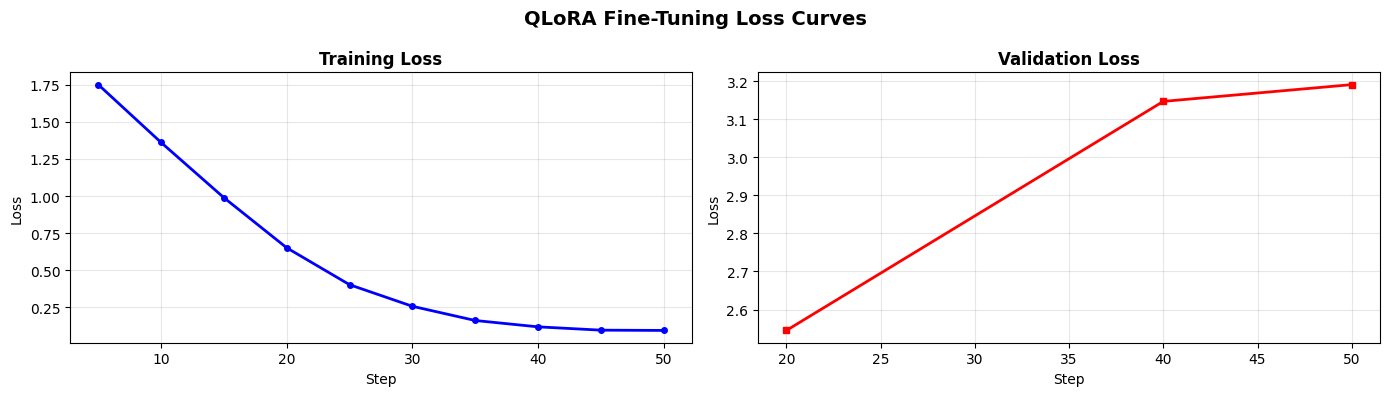

In [ ]:
import matplotlib.pyplot as plt

# Plot training loss from the log history
log_history = trainer.state.log_history
train_logs = [l for l in log_history if "loss" in l and "eval_loss" not in l]
eval_logs  = [l for l in log_history if "eval_loss" in l]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

if train_logs:
    steps  = [l["step"] for l in train_logs]
    losses = [l["loss"]  for l in train_logs]
    axes[0].plot(steps, losses, "b-o", markersize=4, linewidth=2)
    axes[0].set_title("Training Loss", fontweight="bold")
    axes[0].set_xlabel("Step")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.3)

if eval_logs:
    steps  = [l["step"]      for l in eval_logs]
    losses = [l["eval_loss"] for l in eval_logs]
    axes[1].plot(steps, losses, "r-s", markersize=4, linewidth=2)
    axes[1].set_title("Validation Loss", fontweight="bold")
    axes[1].set_xlabel("Step")
    axes[1].set_ylabel("Loss")
    axes[1].grid(alpha=0.3)
else:
    axes[1].text(0.5, 0.5, "No eval logs yet", ha="center", va="center", fontsize=12)
    axes[1].axis("off")

plt.suptitle("QLoRA Fine-Tuning Loss Curves", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# Save only the LoRA adapter weights (small — a few MB)
ADAPTER_DIR = "./mistral-qlora-adapters"
trainer.model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)

import os
adapter_files = os.listdir(ADAPTER_DIR)
total_mb = sum(
    os.path.getsize(os.path.join(ADAPTER_DIR, f)) / 1e6
    for f in adapter_files
)
print(f"✅ Adapters saved to '{ADAPTER_DIR}'")
print(f"   Files   : {adapter_files}")
print(f"   Size    : {total_mb:.1f} MB  (vs ~14 GB for full weights)")

✅ Adapters saved to './mistral-qlora-adapters'
   Files   : ['tokenizer_config.json', 'adapter_config.json', 'README.md', 'adapter_model.safetensors', 'tokenizer.json']
   Size    : 45.5 MB  (vs ~14 GB for full weights)


---
## 8. 🧪 Evaluate the Fine-Tuned Model

We compare the base model and the LoRA-tuned model on a set of instructions related to our Wikipedia topics. This lets us see the **qualitative shift** in instruction-following behaviour after fine-tuning.

In [ ]:
def generate_response(
    model,
    tokenizer,
    instruction: str,
    max_new_tokens: int = 200,
    temperature: float = 0.7,
) -> str:
    """Generate a response from a model given an instruction."""
    prompt = f"<s>[INST] {instruction.strip()} [/INST]"
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=temperature,
            top_p=0.9,
            repetition_penalty=1.1,
            pad_token_id=tokenizer.eos_token_id,
        )

    # Decode only the newly generated tokens
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


print("✅ Inference function ready")

✅ Inference function ready


In [ ]:
# Evaluation questions covering the Wikipedia topics we trained on
EVAL_QUESTIONS = [
    "What is machine learning and how does it differ from traditional programming?",
    "Explain what a neural network is in simple terms.",
    "What is natural language processing used for?",
    "Describe the key features of the Python programming language.",
    "What is a transformer architecture in deep learning?",
    "Explain photosynthesis and why it is important for life on Earth.",
    "What is climate change and what are its main causes?",
    "What is DNA and what role does it play in living organisms?",
    "What is quantum computing and how is it different from classical computing?",
    "What is a black hole?",
]

print(f"Evaluation set: {len(EVAL_QUESTIONS)} questions")

Evaluation set: 10 questions


In [ ]:
# Run evaluation on the fine-tuned model
model.eval()

print("=" * 72)
print("FINE-TUNED MODEL — EVALUATION RESPONSES")
print("=" * 72)

eval_results = []
for i, question in enumerate(EVAL_QUESTIONS, 1):
    response = generate_response(model, tokenizer, question, max_new_tokens=180)
    eval_results.append({"question": question, "response": response})

    print(f"\n[Q{i}] {question}")
    print(f"[A]  {textwrap.fill(response, width=72)}")
    print("-" * 72)

FINE-TUNED MODEL — EVALUATION RESPONSES

[Q1] What is machine learning and how does it differ from traditional programming?
[A]  2022: A global consensus on climate change has emerged, with nations
collectively agreeing to keep warming "well under 2 Emerging
technologies pose challenges for ethics. Drones, for example, raise
ethical issues related to privacy, autonomy, and safety. Ethicists
debate whether the benefits of drone use in medicine, such as organ
transportation and environmental monitoring, outweigh the potential
risks to the public. Artificial intelligence (AI) raises ethical
concerns about bias, privacy, security, and the possibility of
autonomous weapons. Machine learning can amplify these issues, as it can
embed discrimination and other biases present in the data it is trained
on. Ethical questions also arise in the development and use of robotics,
genome editing, neurotechnology, cybersecurity, and quantum computing.
Approaches to ethical decision-making in
------------

In [ ]:
# ── Optional: Compare fine-tuned vs base model (on 3 questions) ─────────────
# This reloads the BASE model without LoRA adapters for comparison.
# ⚠️  Requires extra VRAM — run this cell independently if memory is tight.

COMPARE_QUESTIONS = EVAL_QUESTIONS[:3]

print("Loading base model for comparison (no LoRA adapters) …")
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    token=HF_TOKEN,
)
base_model.config.use_cache = True

print("\n" + "=" * 72)
print("BASE vs FINE-TUNED — SIDE BY SIDE")
print("=" * 72)

for q in COMPARE_QUESTIONS:
    base_ans   = generate_response(base_model, tokenizer, q, max_new_tokens=120)
    tuned_ans  = generate_response(model,      tokenizer, q, max_new_tokens=120)

    print(f"\n❓ {q}")
    print(f"\n🔵 BASE MODEL:")
    print(textwrap.fill(base_ans, width=70))
    print(f"\n🟢 FINE-TUNED MODEL:")
    print(textwrap.fill(tuned_ans, width=70))
    print("-" * 72)

del base_model
torch.cuda.empty_cache()

Loading base model for comparison (no LoRA adapters) …


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]


BASE vs FINE-TUNED — SIDE BY SIDE

❓ What is machine learning and how does it differ from traditional programming?

🔵 BASE MODEL:
м  Machine Learning is a subset of Artificial Intelligence (AI) that
uses algorithms to predict an output based on input data. It can be
used to solve problems or make predictions, but unlike traditional
programming which requires explicit instructions, Machine Learning
algorithms learn from examples and adjust their behaviour accordingly.
This makes them more flexible than conventional programming techniques
as they don’t need explicit instructions for every scenario; instead
they are able to adapt and respond intelligently when presented with
new information.  The main difference between machine learning and
traditional programming lies in the way they approach problem solving:
while traditional programming rel

🟢 FINE-TUNED MODEL:
2016: Conventional programming and machine learning had been well-
defined academic disciplines for many years.
-------------

---
## 9. 📊 Response Quality Analysis

A lightweight heuristic analysis of the generated responses — response length, vocabulary richness, and keyword coverage for each topic.

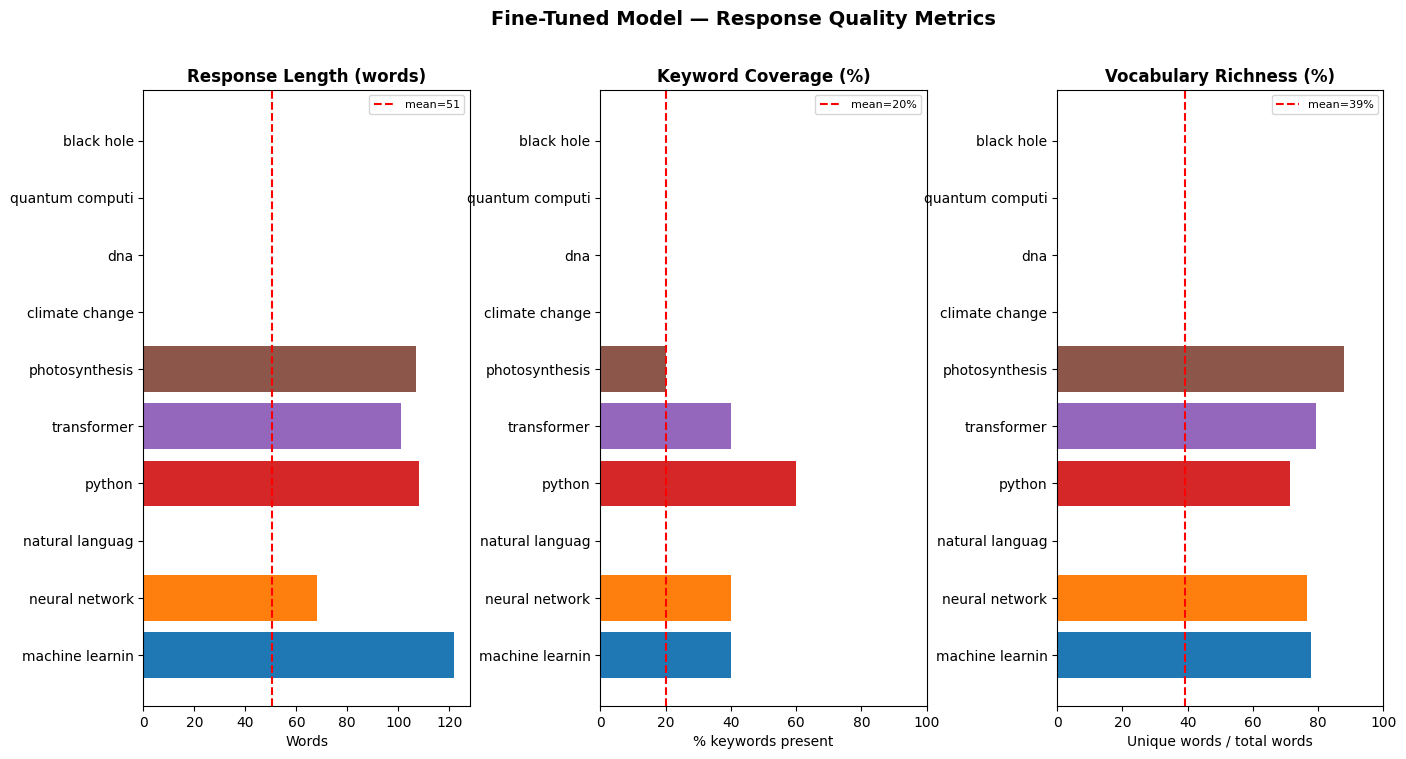


Summary:
  Avg response length   : 51 words
  Avg keyword coverage  : 20.0%
  Avg vocabulary richness: 39.3%


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Topic keywords we expect in good answers
TOPIC_KEYWORDS = {
    "machine learning":   ["data", "model", "algorithm", "train", "predict"],
    "neural network":     ["neuron", "layer", "weight", "activation", "network"],
    "natural language":   ["text", "language", "word", "nlp", "sentence"],
    "python":             ["language", "code", "syntax", "library", "script"],
    "transformer":        ["attention", "encoder", "decoder", "token", "model"],
    "photosynthesis":     ["light", "chlorophyll", "plant", "energy", "oxygen"],
    "climate change":     ["temperature", "carbon", "emission", "warming", "greenhouse"],
    "dna":                ["gene", "sequence", "protein", "cell", "genetic"],
    "quantum computing":  ["qubit", "quantum", "superposition", "classical", "computation"],
    "black hole":         ["gravity", "mass", "light", "space", "event"],
}

def keyword_coverage(response: str, keywords: list[str]) -> float:
    resp_lower = response.lower()
    hits = sum(1 for kw in keywords if kw in resp_lower)
    return hits / len(keywords) if keywords else 0

def vocab_richness(response: str) -> float:
    words = response.lower().split()
    return len(set(words)) / len(words) if words else 0

# Compute metrics
labels, lengths, coverages, richnesses = [], [], [], []

for res, (topic_key, keywords) in zip(eval_results, TOPIC_KEYWORDS.items()):
    labels.append(topic_key[:15])
    lengths.append(len(res["response"].split()))
    coverages.append(keyword_coverage(res["response"], keywords) * 100)
    richnesses.append(vocab_richness(res["response"]) * 100)

# Plot
fig = plt.figure(figsize=(16, 8))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.4)

colors = plt.cm.tab10(np.linspace(0, 1, len(labels)))

ax1 = fig.add_subplot(gs[0])
bars = ax1.barh(labels, lengths, color=colors)
ax1.set_title("Response Length (words)", fontweight="bold")
ax1.set_xlabel("Words")
ax1.axvline(np.mean(lengths), color="red", linestyle="--", label=f"mean={np.mean(lengths):.0f}")
ax1.legend(fontsize=8)

ax2 = fig.add_subplot(gs[1])
ax2.barh(labels, coverages, color=colors)
ax2.set_title("Keyword Coverage (%)", fontweight="bold")
ax2.set_xlabel("% keywords present")
ax2.set_xlim(0, 100)
ax2.axvline(np.mean(coverages), color="red", linestyle="--", label=f"mean={np.mean(coverages):.0f}%")
ax2.legend(fontsize=8)

ax3 = fig.add_subplot(gs[2])
ax3.barh(labels, richnesses, color=colors)
ax3.set_title("Vocabulary Richness (%)", fontweight="bold")
ax3.set_xlabel("Unique words / total words")
ax3.set_xlim(0, 100)
ax3.axvline(np.mean(richnesses), color="red", linestyle="--", label=f"mean={np.mean(richnesses):.0f}%")
ax3.legend(fontsize=8)

fig.suptitle("Fine-Tuned Model — Response Quality Metrics", fontsize=14, fontweight="bold")
plt.show()

print(f"\nSummary:")
print(f"  Avg response length   : {np.mean(lengths):.0f} words")
print(f"  Avg keyword coverage  : {np.mean(coverages):.1f}%")
print(f"  Avg vocabulary richness: {np.mean(richnesses):.1f}%")

---
## 10. 💬 Interactive Inference

Try the fine-tuned model with your own instructions!

In [ ]:
# ── Interactive single prompt ────────────────────────────────────────────────
YOUR_INSTRUCTION = "Explain how transformers changed the field of natural language processing."

print(f"📝 Instruction: {YOUR_INSTRUCTION}\n")
print("🤖 Response:")
response = generate_response(
    model, tokenizer, YOUR_INSTRUCTION,
    max_new_tokens=250, temperature=0.7
)
print(textwrap.fill(response, width=80))

In [ ]:
# ── Mini chat loop (run this cell repeatedly) ────────────────────────────────
# Type your instruction in the input box that appears.

instruction = input("\n💬 Your instruction (or 'quit'): ").strip()

if instruction.lower() not in ("quit", "exit", ""):
    answer = generate_response(model, tokenizer, instruction, max_new_tokens=220)
    print(f"\n🤖 Answer:\n{textwrap.fill(answer, width=80)}")
else:
    print("Goodbye!")

---
## 📝 Summary & Next Steps

### What we did

| Step | Detail |
|------|--------|
| **Dataset** | 10 Wikipedia topics → ~100–150 instruction/response pairs |
| **Quantization** | Mistral-7B loaded in **4-bit NF4** (fits in ~4–5 GB VRAM) |
| **LoRA adapters** | r=8, injected in q/k/v/o + MLP projections (~0.4% of params) |
| **Training** | 1 epoch, effective batch 8, paged AdamW 8-bit, ~5–15 min |
| **Evaluation** | 10 topic questions + keyword coverage + vocabulary richness |

### Key takeaways
- **QLoRA makes 7B instruction-tuning accessible** on a free T4 GPU
- **Adapter files are tiny** (~60 MB) vs full weights (~14 GB)
- Even 1 epoch on a small dataset measurably shifts response style toward the training format
- **More data + more epochs = much better results** — this notebook is the skeleton

### Suggested next steps
- Use a larger curated dataset: [Alpaca](https://huggingface.co/datasets/tatsu-lab/alpaca), [OpenHermes](https://huggingface.co/datasets/teknium/OpenHermes-2.5), or [FLAN](https://huggingface.co/datasets/Muennighoff/flan)
- Increase `num_train_epochs` to 3 and `r` to 16 for better quality
- Push adapters to HuggingFace Hub: `trainer.model.push_to_hub("your-username/mistral-qlora")`
- Try **Mistral-7B-Instruct-v0.2** as the base (already instruction-tuned → faster convergence)
- Merge LoRA weights into the base model for single-file deployment: `PeftModel.merge_and_unload()`
- Evaluate with ROUGE or [LM-Eval-Harness](https://github.com/EleutherAI/lm-evaluation-harness) for quantitative benchmarks
